# INITIAL SETTINGS AND LIBRARIES

In [ ]:
#===============================================LIBRARIES===============================================

import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from datetime import date
from recidivism

#===============================================PATH AND SELECT COLUMNS FOR DF===============================================

data_path = Path(r'../data/data_dummy.xlsx')

df = pd.read_excel(data_path, sheet_name = 'costumer_service')

df_incidents = df.drop(columns = ['REQUISITANTE', 
                                   'PRIORIDADE',  
                                   'PERIODO', 
                                   'DIADASEMANA', 
                                   'TEMPODERESPOSTA', 
                                   'SLA', 
                                   'SLAATRIBUICAO'])

#===============================================PREVIEW===============================================

print(f'{'='*50}{'DATABASE HEAD'}{'='*50}')
print(df_incidents.head(5))

print('\n')
print(f'{'='*50}{'DATABASE DATA TYPES'}{'='*50}')
print(df_incidents.dtypes)

#===============================================BASIC STATS==============================================

df_incidents.describe()

==================================================DATABASE HEAD==================================================
   TICKETID    AGENTE ECSHORTNAME    CATEGORIA     INCIDENTE     PROBLEMA  \
0   1612509  AGENTE 1     LOCAL 1  CATEGORIA 1   INCIDENTE 1   PROBLEMA 1   
1   1614167  AGENTE 1     LOCAL 1  CATEGORIA 4  INCIDENTE 27  PROBLEMA 50   
2   1614175  AGENTE 1     LOCAL 1  CATEGORIA 4  INCIDENTE 27  PROBLEMA 50   
3   1623370  AGENTE 1     LOCAL 1  CATEGORIA 4  INCIDENTE 27  PROBLEMA 50   
4   1630632  AGENTE 6     LOCAL 1  CATEGORIA 3  INCIDENTE 16  PROBLEMA 36   

     SOLUCAO NECESSARIOFIELDSERVICE            CRIADOEM         ASSOCIADOEM  \
0  SOLUCAO 1                    NaN 2026-07-01 14:05:35 2026-07-01 14:05:35   
1  SOLUCAO 8                    NaN 2026-07-03 18:25:36 2026-07-03 18:25:36   
2  SOLUCAO 8                    NaN 2026-07-03 18:35:38 2026-07-03 18:35:38   
3  SOLUCAO 8                    NaN 2026-07-16 18:50:35 2026-07-16 19:00:42   
4  SOLUCAO 7                

,TICKETID,CRIADOEM,ASSOCIADOEM,SOLUCIONADOEM
count,6.363800e+04,63638,63638,63638
mean,1.666164e+06,2026-09-10 21:52:00.577328128,2026-09-10 22:33:32.288994048,2026-09-11 03:36:03.625679616
min,1.529015e+06,2026-03-03 16:54:03,2026-03-03 16:56:06,2026-07-01 00:08:03
25%,1.641037e+06,2026-08-10 12:56:04,2026-08-10 13:02:34.249999872,2026-08-10 16:54:24.750000128
50%,1.667304e+06,2026-09-13 23:44:34.500000,2026-09-14 00:28:24,2026-09-14 09:12:33
75%,1.691554e+06,2026-10-12 22:52:42.249999872,2026-10-12 23:37:14,2026-10-13 11:06:48.249999872
max,1.716751e+06,2026-11-12 23:49:35,2026-11-12 23:49:35,2026-11-12 23:58:42
std,2.978576e+04,NaN,NaN,NaN


# DEFFINTION OF THE DIFERENTS DATASETS

In [2]:
#===============================================ORIGINAL DATAFRAME===============================================

df_incidents['CHAVE'] = df_incidents.apply( # creation of an key column with the local name and lane name of each place
    lambda row: f"{row['ECSHORTNAME']} - {row['PISTA']}",
    axis=1) 

df_incidents['QT_FIELD'] = df_incidents.apply( # creation of an column for count the times that was necessary the action of an field agent                     
    lambda row_field: 1 if row_field.NECESSARIOFIELDSERVICE == 'sim' else 0, 
    axis = 1) 

#===============================================DATAFRAME FOCUSED IN DAYS BETWNENN ACCIDENTS===============================================
# the bellow process is focused in the creation of an column that measures the time between the last incident and the most recent
# this will allow analysis based in the quality of the remote costumer service in solving the problems related to the comercial establishment

df_incidents_days = df_incidents.copy() 

df_incidents_days = df_incidents_days.sort_values(
    by=['CHAVE', 
        'CRIADOEM']
    ).reset_index(drop=True) 

df_incidents_days['ULTIMA_SOLUCAO'] = df_incidents_days.groupby('CHAVE')['SOLUCIONADOEM'].shift(1) 

df_incidents_days['INTERVALO_INCIDENTE'] = (
    df_incidents_days['CRIADOEM'] - df_incidents_days['ULTIMA_SOLUCAO']
    ).dt.total_seconds() / 86400 # this step is neccessary to convert the time between incidents in days

df_incidents_days['INTERVALO_INCIDENTE'] = df_incidents_days['INTERVALO_INCIDENTE'].round(2)

df_incidents_days = df_incidents_days.dropna(
    subset=['ULTIMA_SOLUCAO']
    ) # exclude that incidents that not have an last sollution. That means they are still in the resolution stage

df_incidents_days = df_incidents_days[
    df_incidents_days['INTERVALO_INCIDENTE'] > 0
    ].reset_index(drop=True) # exclude the first incidents in the dataset, because they don't have an previous incident

#===============================================DATAFRAME FOCCUSED IN FREQUENCY OF ACCIDENT OCURRENCY===============================================
# the dataset bellow creates the possibility of the analysis focused in the frequency of incidents in the commercial estabilishtments and their lanes
# an simple copy of the original dataframe is sufficient to this analysis

df_incidents_frequency = df_incidents.copy()


VERIFICAÇÃO DE NORMALIDADE E OUTLIERS COM RELAÇÃO A INTERVALO

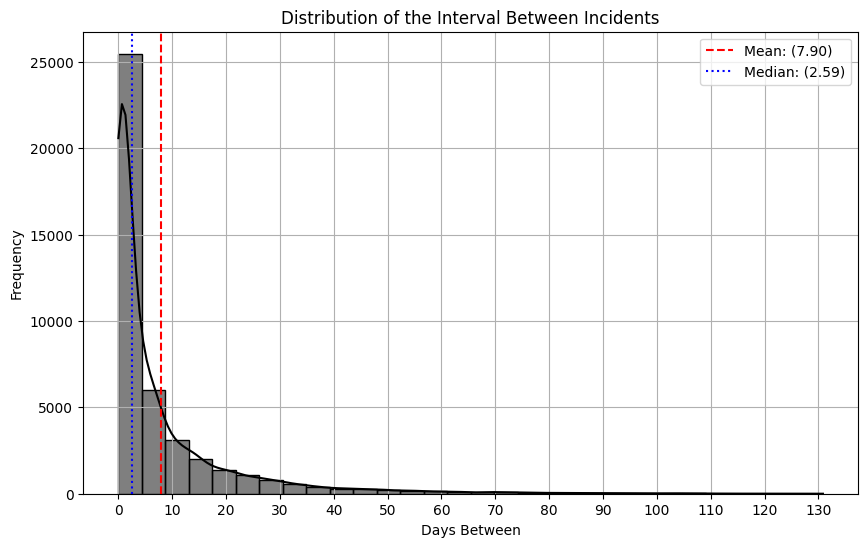

Coeficiente de assimetria: 8.985565927654608
Mediana dos dados: 2.59


In [ ]:
#===============================================CALCULARION OF THE AVERAGE, MEDIAN AND STANDARD DEVIATION===============================================

avg_days = round(df_incidents_days['INTERVALO_INCIDENTE'].mean(), 2)
median_days = round(df_incidents_days['INTERVALO_INCIDENTE'].median(), 2)
std_days = round(np.std(df_incidents_days['INTERVALO_INCIDENTE']), 2)

#===============================================HISTOGRAM OF DAYS BETWEEN INCIDENTS===============================================
# we use this type of visualization in this situation to verify the distribution of the data and
# by this, we can see evidence of asymmetric or normal distribuition

plt.figure(figsize=(10, 6))
sns.histplot(data=df_incidents_days, 
             x='INTERVALO_INCIDENTE', 
             kde=True,
             color='black',
             bins=30
             )

plt.title('Distribution of the Interval Between Incidents')
plt.xlabel('Days Between')
plt.ylabel('Frequency') #labels and title set

plt.axvline(avg_days, 
            color = 'r', 
            linestyle = 'dashed', 
            linewidth = 1.5,
            label=f'Average: ({avg_days:.2f})'
            ) # label of the avereage line

plt.axvline(median_days, 
            color = 'b', 
            linestyle = 'dotted', 
            linewidth = 1.5,
            label=f'Median: ({median_days:.2f})'
            ) # label of the median line

val_min = df_incidents_days['INTERVALO_INCIDENTE'].min()
val_max = df_incidents_days['INTERVALO_INCIDENTE'].max()

plt.xticks(np.arange(start=val_min, 
                     stop=val_max + 1, 
                     step=10)
           ) # set the labls of x axis by the step 10

plt.legend()
plt.grid(True)
plt.show()

#===============================================BOWLEY'S COEFFICIENT OF SKEWNESS===============================================

q1_days = round(df_incidents_days['INTERVALO_INCIDENTE'].quantile(0.25), 2)
q2_days = round(df_incidents_days['INTERVALO_INCIDENTE'].quantile(0.75), 2)
iqr_days = round(q2_days-q1_days, 2)

skewness_days = round(((q2_days+q1_days-(2*median_days)/(q2_days-q1_days))), 2)

print(f"Coeficiente de assimetria: {skewness_days}")
print(f"Mediana dos dados: {median_days}")

ANÁLISE DE REINCIDÊNCIA COM BASE EM INTERVALO

In [ ]:


if assimetria_qualidade > 0 or assimetria_qualidade >= 0.5 or assimetria_qualidade <= -0.5: 
    
    df_incidentes_qualidade = df_incidentes_qualidade[ 
        df_incidentes_qualidade['INTERVALO_INCIDENTE'] <= mediana_qualidade
        ].reset_index(drop=True)
    
elif assimetria_qualidade == 0:
    
    df_incidentes_qualidade = df_incidentes_qualidade[ 
        df_incidentes_qualidade['INTERVALO_INCIDENTE'] <= media_qualidade
        ].reset_index(drop=True)
    
else:
    
    print(f'='*100)
    print(f'Reavaliar o caso particularmente. Não houve sinais de assimetria ou simetria na amostra\n'
          f'Pode caber uma análise por valor p\nValor do coeficiente de assimetria: {assimetria_qualidade:.2f}')
    print(f'='*100)



reincid_qualidadeData = df_incidentes_qualidade.groupby('CHAVE').agg({ 
                                                                      
    'INCIDENTE': lambda row_inc: row_inc.mode()[0],
    'PROBLEMA': lambda row_pro: row_pro.mode()[0],
    'SOLUCAO': lambda row_sol: row_sol.mode()[0],
    'AGENTE': lambda row_ag: row_ag.mode()[0],
    'INTERVALO_INCIDENTE': 'median',
    'QT_FIELD': 'sum',
})

reincid_qualidadeData_top50 = reincid_qualidadeData.copy().nsmallest(50,'INTERVALO_INCIDENTE') 
print(reincid_qualidadeData_top50)

                           INCIDENTE     PROBLEMA    SOLUCAO    AGENTE  \
CHAVE                                                                    
LOCAL 1 - PISTA 341     INCIDENTE 27  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 377     INCIDENTE 27  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 102 - PISTA 128   INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 102 - PISTA 2234  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 102 - PISTA 532   INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 2589  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 3078  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 3079  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 3080  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 107 - PISTA 579   INCIDENTE 14  PROBLEMA 44  SOLUCAO 7  AGENTE 6   
LOCAL 107 - PISTA 580   INCIDENTE 14  PROBLEMA 44  SOLUCAO 7  AGENTE 6   
LOCAL 107 - PISTA 584   INCIDENTE 14  

VERIFICAÇÃO DE NORMALIDADE E OUTLIERS COM RELAÇÃO A QUANTIDADE DE CHAMADOS

                         INCIDENTE     PROBLEMA    SOLUCAO    AGENTE  \
CHAVE                                                                  
LOCAL 1 - PISTA 1     INCIDENTE 27  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1340  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1358  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1394  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1601  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
...                            ...          ...        ...       ...   
LOCAL 99 - PISTA 781  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7  AGENTE 1   
LOCAL 99 - PISTA 782  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 99 - PISTA 801  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 99 - PISTA 805  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7  AGENTE 8   
LOCAL 99 - PISTA 820  INCIDENTE 28  PROBLEMA 50  SOLUCAO 7  AGENTE 8   

                      QT_CHAMADOS  QT_FIELD  
CHAVE            

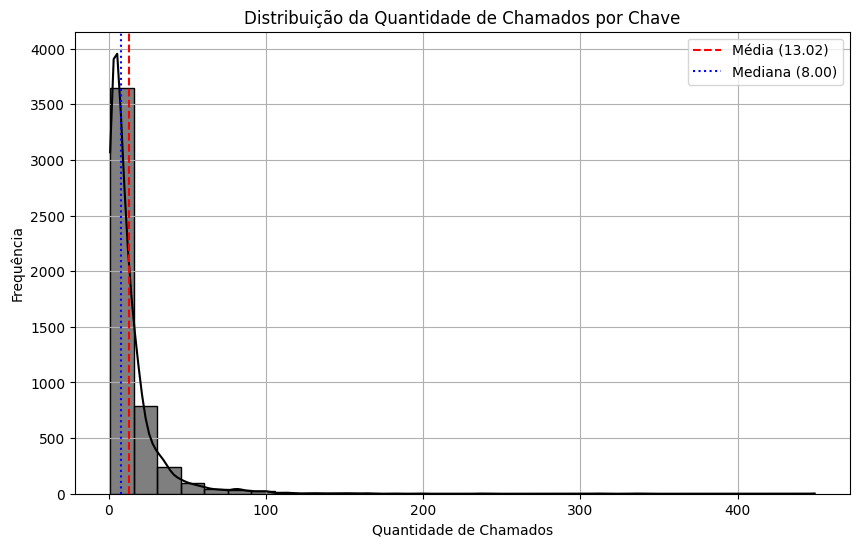

Mediana: 8.00
Coeficiente de assimetria: 0.23076923076923078


In [ ]:


reincid_chamadosData = df_incidentes_chamados.groupby('CHAVE').agg({
    'INCIDENTE': lambda row_inc: row_inc.mode()[0],
    'PROBLEMA': lambda row_pro: row_pro.mode()[0],
    'SOLUCAO': lambda row_sol: row_sol.mode()[0],
    'AGENTE': lambda row_ag: row_ag.mode()[0],
    'TICKETID': 'count', 
    'QT_FIELD': 'sum',
}).rename(columns={'TICKETID': 'QT_CHAMADOS'}) 

print(reincid_chamadosData)



media_chamados = reincid_chamadosData['QT_CHAMADOS'].mean()
mediana_chamados = reincid_chamadosData['QT_CHAMADOS'].median()



plt.figure(figsize=(10, 6))
sns.histplot(
    data=reincid_chamadosData,
    x='QT_CHAMADOS',
    kde=True,
    color='black',
    bins=30
)
plt.title('Distribuição da Quantidade de Chamados por Chave')
plt.xlabel('Quantidade de Chamados')
plt.ylabel('Frequência')

plt.axvline(
    media_chamados, 
    color='r', 
    linestyle='dashed', 
    linewidth=1.5,
    label=f'Média ({media_chamados:.2f})'
)
plt.axvline(
    mediana_chamados, 
    color='b', 
    linestyle='dotted', 
    linewidth=1.5,
    label=f'Mediana ({mediana_chamados:.2f})'
)

plt.legend()
plt.grid(True)
plt.show()



q1_ch = reincid_chamadosData['QT_CHAMADOS'].quantile(0.25)
q3_ch = reincid_chamadosData['QT_CHAMADOS'].quantile(0.75)
iqr_ch = q3_ch - q1_ch
ls_ch = q3_ch + 1.5 * iqr_ch

over_ls_ch = (reincid_chamadosData['QT_CHAMADOS'] > ls_ch).sum()
total_chaves = reincid_chamadosData.shape[0]
outliers_pct = (over_ls_ch / total_chaves) * 100

assimetria_chamados = (q3_ch + q1_ch - (2 * mediana_chamados)) / iqr_ch if iqr_ch != 0 else 0

print(f"Mediana: {mediana_chamados:.2f}")
print(f"Coeficiente de assimetria: {assimetria_chamados}")


In [ ]:

if 'index' in reincid_chamadosData.columns:
    reincid_chamadosData = reincid_chamadosData.rename(columns={'index': 'CHAVE'})






if abs(assimetria_chamados) >= 0.5:
    reincid_chamadosData = reincid_chamadosData[
        reincid_chamadosData['QT_CHAMADOS'] >= mediana_chamados
    ]

elif abs(assimetria_chamados) < 0.5:
    reincid_chamadosData = reincid_chamadosData[
        reincid_chamadosData['QT_CHAMADOS'] >= media_chamados
    ]

else:
    print('=' * 100)
    print(f'Reavaliar o caso particularmente. Valor do coeficiente de assimetria: {assimetria_chamados:.2f}')
    print('=' * 100)

print('=')
print(reincid_chamadosData)

reincid_chamadoData_top50 = (
    reincid_chamadosData.nlargest(50, 'QT_CHAMADOS')
    .reset_index()
)

print(reincid_chamadoData_top50)

=
                         INCIDENTE     PROBLEMA    SOLUCAO     AGENTE  \
CHAVE                                                                   
LOCAL 1 - PISTA 1601  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 1789  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 342   INCIDENTE 27  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 344   INCIDENTE 14  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 41    INCIDENTE 31  PROBLEMA 64  SOLUCAO 7  AGENTE 10   
...                            ...          ...        ...        ...   
LOCAL 99 - PISTA 781  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7   AGENTE 1   
LOCAL 99 - PISTA 782  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 99 - PISTA 801  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 99 - PISTA 805  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7   AGENTE 8   
LOCAL 99 - PISTA 820  INCIDENTE 28  PROBLEMA 50  SOLUCAO 7   AGENTE 8   

                      QT_CHAMADOS  QT_FIELD  
CH

EXTRAÇÃO DOS DADOS

In [ ]:
from datetime import date
from pathlib import Path
import pandas as pd

ext_date = date.today()


def preparar_df(df, data_execucao):
    df_temp = df.copy()
    if 'CHAVE' not in df_temp.columns:
        df_temp = df_temp.reset_index()
    df_temp['DTR'] = data_execucao
    return df_temp

data_dict = {
    'Reincidencia_Qualidade': preparar_df(reincid_qualidadeData, ext_date),
    'Reincidencia_Chamados': preparar_df(reincid_chamadosData, ext_date),
    'Reincidencia_QualidadeTop50': preparar_df(reincid_qualidadeData_top50, ext_date),
    'Reincidencia_ChamadosTop50': preparar_df(reincid_chamadoData_top50, ext_date)
}



ext_unif = Path(r'../output')
ext_unif.mkdir(parents=True, exist_ok=True)


file_path = ext_unif / 'recidivism_database.xlsx'

consolidated_data = {}

for nome, df_novo in data_dict.items():
    
    if file_path.exists():
        try:
            df_existente = pd.read_excel(file_path, sheet_name=nome)
            df_consolidado = pd.concat([df_existente, df_novo], ignore_index=True)
        except ValueError:
            
            df_consolidado = df_novo
    else:
        df_consolidado = df_novo
    
    consolidated_data[nome] = df_consolidado


with pd.ExcelWriter(file_path, engine='xlsxwriter') as writer_xlsx:
    for nome, dados in consolidated_data.items():
        dados.to_excel(writer_xlsx, sheet_name=nome, index=False)
        worksheet = writer_xlsx.sheets[nome]
        max_row, max_col = dados.shape
        column_settings = [{'header': col} for col in dados.columns]
        worksheet.add_table(0, 0, max_row, max_col - 1, {'columns': column_settings, 'style': 'Table Style Medium 9'})
        worksheet.autofit()
        
writer_xlsx.close()

c:\Users\joaop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xlsxwriter\workbook.py:497: UserWarning: Calling close() on already closed file.
  warn("Calling close() on already closed file.")
